In [4]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy
!pip install qiskit-machine-learning
!pip install pennylane scikit-learn matplotlib
!pip install qiskit-algorithms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 3.6 MB/s eta 0:00:00


STEP 2. Parameterized Quantum Circuit & Simulator
Target : -0.8


STEP 4. COBYLA History & Objective


STEP 5. Initial Parameter
Initial Parameter  : 0.2
Initial Prediction : 0.9853515625
Initial Loss       : 3.1874802017211916


STEP 6. COBYLA


STEP 7. Optimization
[001] Theta=  0.2000 Prediction=  0.9805 Loss=  3.170069
[002] Theta=  1.2000 Prediction=  0.3857 Loss=  1.405985
[003] Theta=  2.2000 Prediction= -0.5771 Loss=  0.049663
[004] Theta=  4.2000 Prediction= -0.4941 Loss=  0.093550
[005] Theta=  1.2000 Prediction=  0.3428 Loss=  1.305931
[006] Theta=  2.7000 Prediction= -0.8955 Loss=  0.009122
[007] Theta=  2.9500 Prediction= -0.9883 Loss=  0.035450
[008] Theta=  2.6000 Prediction= -0.8789 Loss=  0.006226
[009] Theta=  2.5000 Prediction= -0.8066 Loss=  0.000044
[010] Theta=  2.3000 Prediction= -0.6621 Loss=  0.019014
[011] Theta=  2.6000 Prediction= -0.8701 Loss=  0.004916
[012] Theta=  2.4500 Prediction= -0.7793 Loss=  0.000429
[013] Theta=  2.5250 Prediction= -0.8135 Loss=  

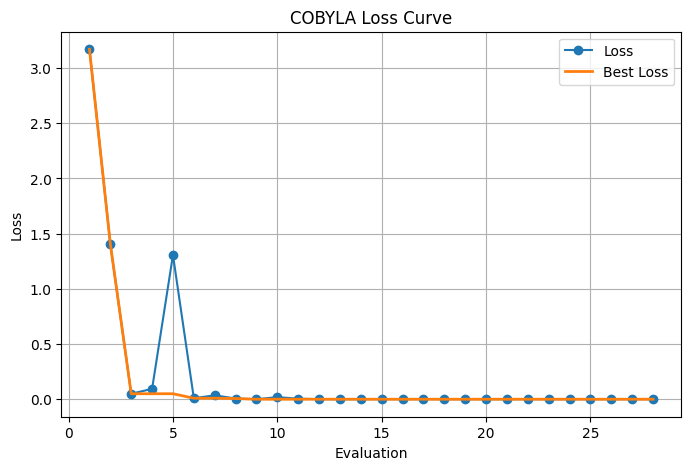

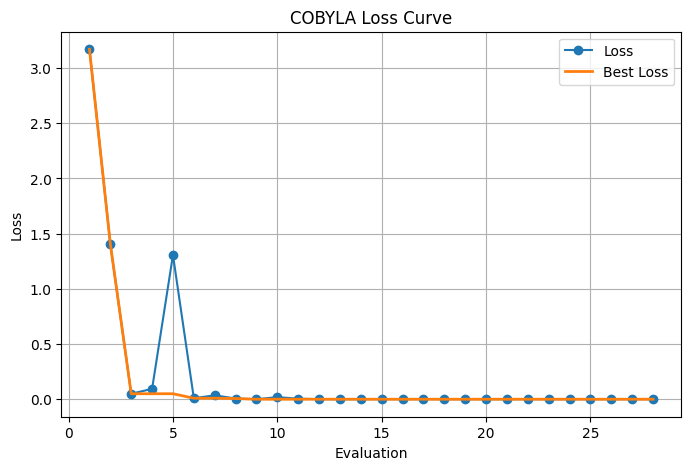

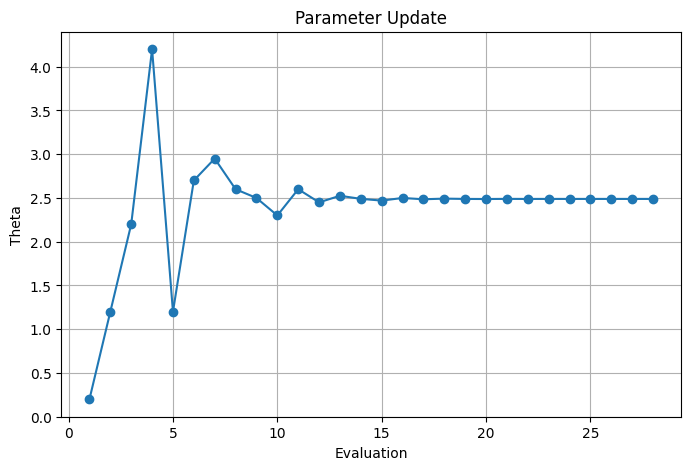

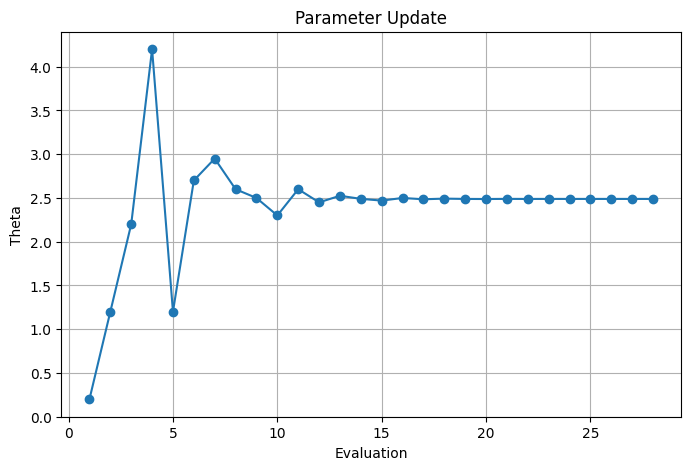

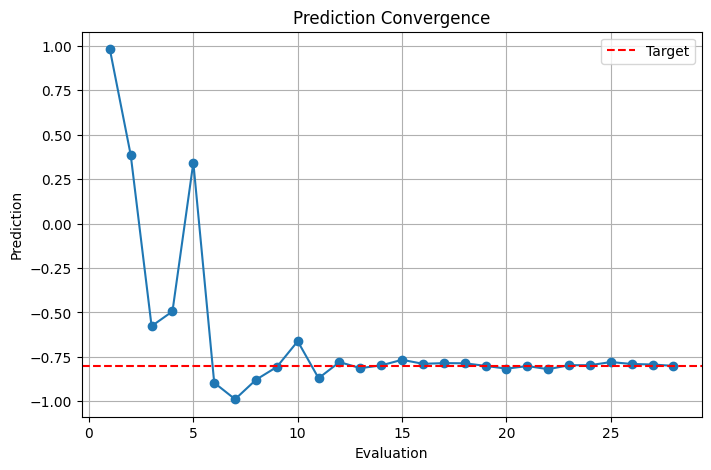

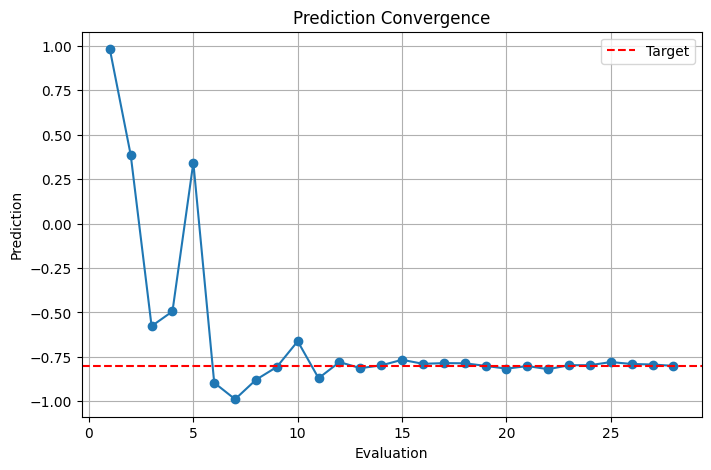

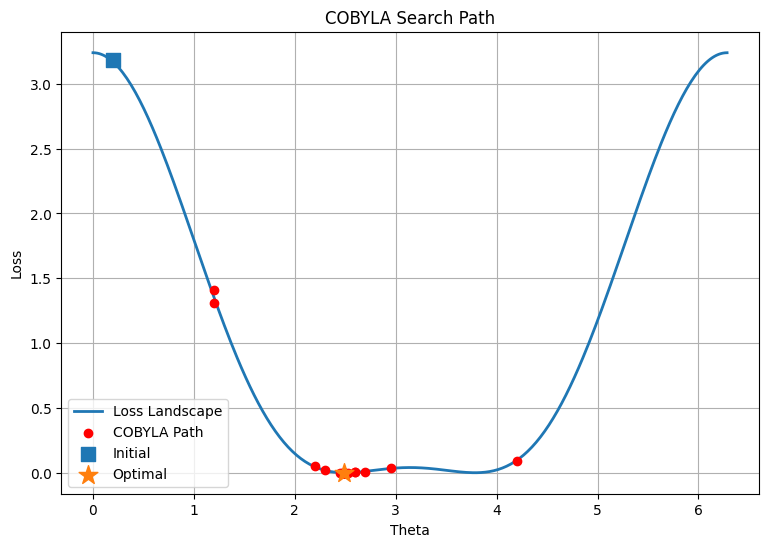

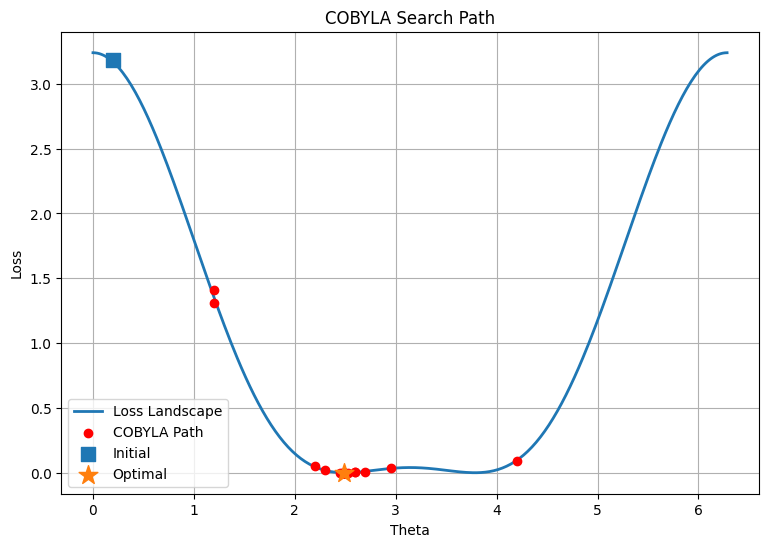



SUMMARY
Initial Parameter   : 0.2
Optimal Parameter   : 2.4890000000000003
Initial Loss        : 3.1874802017211916
Final Loss          : 1.6822814941406613e-05
Prediction          : -0.7958984375
Function Evaluation : 28
Iteration           : None

COBYLA는 Objective Function을 반복 호출하여 Loss가 가장 작은 Parameter를 탐색하였다.
Lab Complete


In [5]:
%matplotlib inline

# ============================================================
# STEP 1. Library Import
# ============================================================

import time
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit import transpile
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_algorithms.optimizers import COBYLA

# ============================================================
# STEP 2. Parameterized Quantum Circuit 생성 및 환경 설정
# ============================================================

print("=" * 80)
print("STEP 2. Parameterized Quantum Circuit & Simulator")
print("=" * 80)

theta = Parameter("θ")
qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()

simulator = AerSimulator()
shots = 2048

# ============================================================
# STEP 3. Prediction & Objective Function 구현
# ============================================================

def predict(theta_value):
    bound = qc.assign_parameters({theta: theta_value})
    compiled = transpile(bound, simulator)
    job = simulator.run(compiled, shots=shots)
    result = job.result()
    counts = result.get_counts()

    p0 = counts.get("0", 0) / shots
    p1 = counts.get("1", 0) / shots
    prediction = p0 - p1
    return prediction

target = -0.8
print("Target :", target)

# ============================================================
# STEP 4. COBYLA History & Objective Function
# ============================================================

print("\n")
print("=" * 80)
print("STEP 4. COBYLA History & Objective")
print("=" * 80)

cobyla_history = {
    "evaluation": [],
    "parameter": [],
    "prediction": [],
    "loss": [],
    "best_loss": []
}

def cobyla_objective(parameters):
    theta_value = float(parameters[0])
    prediction = predict(theta_value)
    loss = (prediction - target) ** 2

    evaluation = len(cobyla_history["evaluation"]) + 1

    cobyla_history["evaluation"].append(evaluation)
    cobyla_history["parameter"].append(theta_value)
    cobyla_history["prediction"].append(prediction)
    cobyla_history["loss"].append(loss)

    current_best = min(cobyla_history["loss"])
    cobyla_history["best_loss"].append(current_best)

    print(
        f"[{evaluation:03d}] "
        f"Theta={theta_value:8.4f} "
        f"Prediction={prediction:8.4f} "
        f"Loss={loss:10.6f}"
    )

    return float(loss)

# ============================================================
# STEP 5. Initial Parameter
# ============================================================

print("\n")
print("=" * 80)
print("STEP 5. Initial Parameter")
print("=" * 80)

initial_point = np.array([0.2])
initial_prediction = predict(initial_point[0])
initial_loss = (initial_prediction - target) ** 2

print("Initial Parameter  :", initial_point[0])
print("Initial Prediction :", initial_prediction)
print("Initial Loss       :", initial_loss)

# ============================================================
# STEP 6. COBYLA 생성
# ============================================================

print("\n")
print("=" * 80)
print("STEP 6. COBYLA")
print("=" * 80)

optimizer = COBYLA(
    maxiter=100,
    rhobeg=1.0,
    tol=1e-6
)

print(optimizer)

# ============================================================
# STEP 7. Optimization
# ============================================================

print("\n")
print("=" * 80)
print("STEP 7. Optimization")
print("=" * 80)

start = time.perf_counter()

result = optimizer.minimize(
    fun=cobyla_objective,
    x0=initial_point
)

elapsed = time.perf_counter() - start

# ============================================================
# STEP 8. Optimization Result
# ============================================================

print("\n")
print("=" * 80)
print("STEP 8. Result")
print("=" * 80)

optimal_theta = float(result.x[0])
optimizer_loss = float(result.fun)
nfev = getattr(result, "nfev", None)
nit = getattr(result, "nit", None)

print("Optimal Theta       :", optimal_theta)
print("Optimizer Loss      :", optimizer_loss)
print("Function Evaluation :", nfev)
print("Iteration           :", nit)
print("Elapsed Time        :", f"{elapsed:.4f} sec")

# ============================================================
# STEP 9. Prediction Verification
# ============================================================

print("\n")
print("=" * 80)
print("STEP 9. Prediction Verification")
print("=" * 80)

final_prediction = predict(optimal_theta)
verified_loss = (final_prediction - target) ** 2

print("Prediction    :", final_prediction)
print("Target        :", target)
print("Verified Loss :", verified_loss)

# ============================================================
# STEP 10. Loss Curve
# ============================================================

fig1 = plt.figure(figsize=(8, 5))

plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["loss"],
    marker="o",
    label="Loss"
)

plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["best_loss"],
    linewidth=2,
    label="Best Loss"
)

plt.xlabel("Evaluation")
plt.ylabel("Loss")
plt.title("COBYLA Loss Curve")
plt.grid(True)
plt.legend()
display(fig1)
plt.show()

# ============================================================
# STEP 11. Parameter Curve
# ============================================================

fig2 = plt.figure(figsize=(8, 5))

plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["parameter"],
    marker="o"
)

plt.xlabel("Evaluation")
plt.ylabel("Theta")
plt.title("Parameter Update")
plt.grid(True)
display(fig2)
plt.show()

# ============================================================
# STEP 12. Prediction Curve
# ============================================================

fig3 = plt.figure(figsize=(8, 5))

plt.plot(
    cobyla_history["evaluation"],
    cobyla_history["prediction"],
    marker="o"
)

plt.axhline(
    y=target,
    color="red",
    linestyle="--",
    label="Target"
)

plt.xlabel("Evaluation")
plt.ylabel("Prediction")
plt.title("Prediction Convergence")
plt.grid(True)
plt.legend()
display(fig3)
plt.show()

# ============================================================
# STEP 13. Loss Landscape & Search Path
# ============================================================

theta_space = np.linspace(0, 2 * np.pi, 300)
landscape = (np.cos(theta_space) - target) ** 2

fig4 = plt.figure(figsize=(9, 6))

plt.plot(
    theta_space,
    landscape,
    label="Loss Landscape",
    linewidth=2
)

plt.scatter(
    cobyla_history["parameter"],
    cobyla_history["loss"],
    color="red",
    zorder=5,
    label="COBYLA Path"
)

plt.scatter(
    [initial_point[0]],
    [initial_loss],
    marker="s",
    s=100,
    zorder=6,
    label="Initial"
)

plt.scatter(
    [optimal_theta],
    [optimizer_loss],
    marker="*",
    s=200,
    zorder=7,
    label="Optimal"
)

plt.xlabel("Theta")
plt.ylabel("Loss")
plt.title("COBYLA Search Path")
plt.grid(True)
plt.legend()
display(fig4)
plt.show()

# ============================================================
# STEP 14. Summary
# ============================================================

print("\n")
print("=" * 80)
print("SUMMARY")
print("=" * 80)

print("Initial Parameter   :", initial_point[0])
print("Optimal Parameter   :", optimal_theta)
print("Initial Loss        :", initial_loss)
print("Final Loss          :", verified_loss)
print("Prediction          :", final_prediction)
print("Function Evaluation :", nfev)
print("Iteration           :", nit)
print()
print("COBYLA는 Objective Function을 반복 호출하여 Loss가 가장 작은 Parameter를 탐색하였다.")
print("=" * 80)
print("Lab Complete")
print("=" * 80)